# Predicting appointment no-shows and refilling the slots

**Question:** if a clinic can only send "confirm you're coming" prompts to a fraction of patients each day, can a model pick the right ones, so that released slots get refilled by nearby standby patients?

**Data:** Kaggle *Medical Appointment No Shows*: 110,527 appointments at public clinics in Vitória, Brazil (April 29 to June 8, 2016). Run `python ml/data/download.py` first.

**Plan**
1. Look at the data and its traps
2. Build features a clinic knows *before* the appointment
3. Split by date (train on the past, test on the future)
4. Compare logistic regression vs gradient boosting
5. Simulate refilling no-show slots: model-picked vs random outreach

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

SRC = Path.cwd().parent / "src"
ART = Path.cwd().parent / "artifacts"
sys.path.insert(0, str(SRC))
from features import load_raw, load_dataset, time_split, FEATURES, TARGET
from train import make_models, evaluate
from simulate import run_policies, budget_curve, catch_rate, DEFAULT_ASSUMPTIONS

plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.3f}".format)

## 1. The data and its traps
- The label is backwards: `No-show = "No"` means the patient **showed up**. We flip it to `no_show = 1` for a missed visit.
- `AppointmentDay` has no time of day (always 00:00), so time of day can't be a feature.
- 5 rows are booked *after* the appointment date and one age is −1; we drop them.

In [2]:
raw = load_raw()
print(f"{len(raw):,} appointments, {raw.patient_id.nunique():,} patients")
print(f"No-show rate: {raw[TARGET].mean():.1%}")
raw[["appt_date", "booked_at", "age_raw", "Gender", "sms_received", "No-show", TARGET]].head()

110,521 appointments, 62,298 patients
No-show rate: 20.2%


,appt_date,booked_at,age_raw,Gender,sms_received,No-show,no_show
0,2016-04-29,2016-04-29 18:38:08,62,F,0,No,0
1,2016-04-29,2016-04-29 16:08:27,56,M,0,No,0
2,2016-04-29,2016-04-29 16:19:04,62,F,0,No,0
3,2016-04-29,2016-04-29 17:29:31,8,F,0,No,0
4,2016-04-29,2016-04-29 16:07:23,56,F,0,No,0


## 2. Features
Everything is known before the visit: lead time (days between booking and appointment), age, the patient's **earlier** no-show history, weekday, the hour the booking was made, and the health/benefit flags.

The history features only count appointments on *earlier* days, so the label never leaks into its own features.

In [3]:
data = load_dataset()
train, val, test = time_split(data)
print(f"train {train.appt_date.min().date()} to {train.appt_date.max().date()}: {len(train):,}")
print(f"val   {val.appt_date.min().date()} to {val.appt_date.max().date()}: {len(val):,}")
print(f"test  {test.appt_date.min().date()} to {test.appt_date.max().date()}: {len(test):,}")
data[FEATURES].describe().T[["mean", "min", "max"]]

train 2016-04-29 to 2016-05-14: 45,905
val   2016-05-16 to 2016-05-20: 21,455
test  2016-05-24 to 2016-06-08: 43,161


,mean,min,max
lead_days,10.184,0.000,179.000
age,37.089,0.000,100.000
prior_appts,1.176,0.000,83.000
prior_noshows,0.184,0.000,15.000
prior_noshow_rate,0.199,0.006,0.906
booked_hour,10.775,6.000,21.000
same_day,0.349,0.000,1.000
is_female,0.650,0.000,1.000
scholarship,0.098,0.000,1.000
hypertension,0.197,0.000,1.000


### Lead time is the strongest single signal
Same-day appointments almost always show. The longer the wait, the more people don't come, which is also the pitch: long waits cause no-shows.

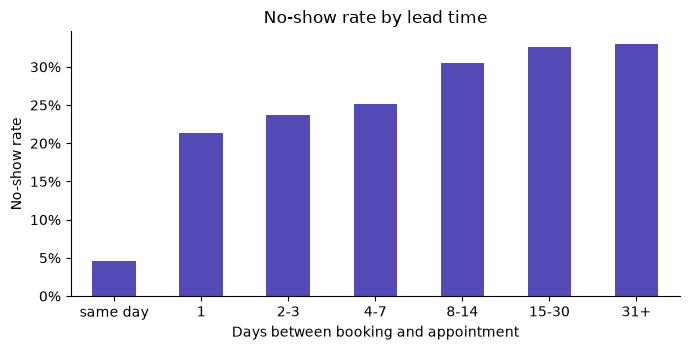

,mean,size
lead_days,,
same day,0.046,38562
1,0.214,5213
2-3,0.237,9462
4-7,0.252,17510
8-14,0.305,12025
15-30,0.326,17371
31+,0.330,10378


In [4]:
bins = [-1, 0, 1, 3, 7, 14, 30, 180]
labels = ["same day", "1", "2-3", "4-7", "8-14", "15-30", "31+"]
by_lead = data.groupby(pd.cut(data.lead_days, bins, labels=labels), observed=True)[TARGET].agg(["mean", "size"])
ax = by_lead["mean"].plot.bar(color="#534AB7")
ax.set_ylabel("No-show rate"); ax.set_xlabel("Days between booking and appointment"); ax.set_title("No-show rate by lead time")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(ART / "lead_time.png", dpi=160); plt.show()
by_lead

### Past behaviour predicts future behaviour

In [5]:
hist = data.assign(history=np.select(
    [data.prior_appts == 0, data.prior_noshows == 0, data.prior_noshows >= 1],
    ["first visit", "always showed before", "missed at least once"], default="other"))
hist.groupby("history")[TARGET].agg(["mean", "size"]).sort_values("mean")

,mean,size
history,,
always showed before,0.188,30119
first visit,0.194,66288
missed at least once,0.269,14114


### A confounder to explain if a judge asks
SMS reminders look like they *increase* no-shows. They don't: reminders were mostly sent for appointments booked far in advance, and those have more no-shows anyway. Within the same lead-time band the relationship actually reverses: patients who got an SMS no-show *less*. We keep the feature, but we never claim "reminders don't work".

In [6]:
data[data.lead_days > 0].groupby([pd.cut(data.lead_days, [0, 7, 14, 30, 180]), "sms_received"], observed=True)[TARGET].mean().unstack().rename(columns={0: "no SMS", 1: "SMS"})

sms_received,no SMS,SMS
lead_days,,
"(0, 7]",0.244,0.238
"(7, 14]",0.338,0.281
"(14, 30]",0.369,0.298
"(30, 180]",0.375,0.302


## 3. Models
Model choice uses the validation week only. Then both models are refit on train+val and scored **once** on the future test weeks.

In [7]:
rows, preds = [], {}
for name, model in make_models().items():
    model.fit(train[FEATURES], train[TARGET])
    v = evaluate(val[TARGET].to_numpy(), model.predict_proba(val[FEATURES])[:, 1])
    model.fit(pd.concat([train, val])[FEATURES], pd.concat([train, val])[TARGET])
    preds[name] = model.predict_proba(test[FEATURES])[:, 1]
    t = evaluate(test[TARGET].to_numpy(), preds[name])
    rows.append({"model": name, "val_auc": v["auc"], "test_auc": t["auc"], "test_brier": t["brier"], "top20_catch_rate": t["top20_catch_rate"]})
results = pd.DataFrame(rows).set_index("model")
print("Brier of always predicting the base rate:", round(test[TARGET].mean() * (1 - test[TARGET].mean()), 4))
results

Brier of always predicting the base rate: 0.1526


,val_auc,test_auc,test_brier,top20_catch_rate
model,,,,
logistic_regression,0.733,0.728,0.139,0.368
gradient_boosting,0.739,0.735,0.138,0.384


**How to read this:** AUC around 0.73 is moderate, and typical for this dataset. That's honest and it's enough to be useful: the top 20% riskiest appointments contain far more than 20% of the no-shows (see `top20_catch_rate`).

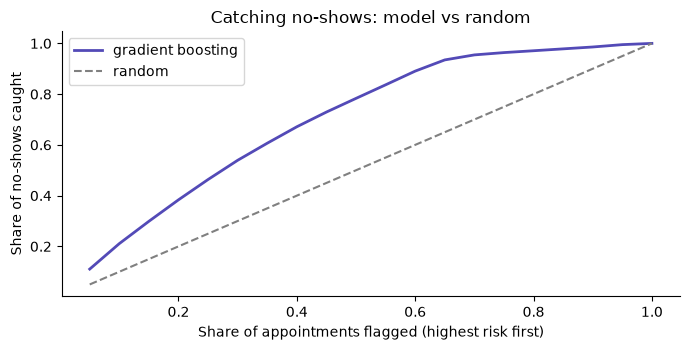

In [8]:
best = results.test_auc.idxmax(); p = preds[best]; y = test[TARGET].to_numpy()
fracs = np.linspace(0.05, 1, 20)
plt.plot(fracs, [catch_rate(y, p, f) for f in fracs], label=f"{best.replace('_', ' ')}", color="#534AB7", lw=2)
plt.plot(fracs, fracs, "--", color="gray", label="random")
plt.xlabel("Share of appointments flagged (highest risk first)"); plt.ylabel("Share of no-shows caught")
plt.title("Catching no-shows: model vs random"); plt.legend(); plt.tight_layout()
plt.savefig(ART / "catch_curve.png", dpi=160); plt.show()

### Calibration
The simulation uses predicted probabilities, so they should mean what they say. The ranking is what matters most here (who gets prompted first), but we still check.

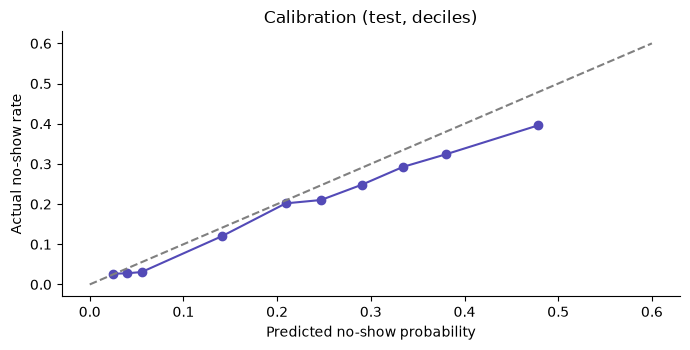

,predicted,actual
bin,,
"(0.00395, 0.0337]",0.025,0.027
"(0.0337, 0.0453]",0.040,0.028
"(0.0453, 0.0728]",0.055,0.031
"(0.0728, 0.189]",0.141,0.120
"(0.189, 0.228]",0.209,0.202
"(0.228, 0.267]",0.247,0.210
"(0.267, 0.312]",0.290,0.248
"(0.312, 0.356]",0.334,0.293
"(0.356, 0.409]",0.380,0.324


In [9]:
cal = pd.DataFrame({"p": p, "y": y}); cal["bin"] = pd.qcut(cal.p, 10, duplicates="drop")
c = cal.groupby("bin", observed=True).agg(predicted=("p", "mean"), actual=("y", "mean"))
plt.plot(c.predicted, c.actual, "o-", color="#534AB7"); plt.plot([0, 0.6], [0, 0.6], "--", color="gray")
plt.xlabel("Predicted no-show probability"); plt.ylabel("Actual no-show rate"); plt.title("Calibration (test, deciles)")
plt.tight_layout(); plt.show(); c

The model ranks well but slightly **over-predicts** in the test weeks: the no-show rate in those weeks was 18.8%, lower than the ~21% it trained on. That's ordinary drift between periods. Since the simulation compares model vs random on the *same* actual outcomes, the comparison isn't affected; only absolute probabilities would need recalibrating on a clinic's own recent data.

### What the model relies on
Permutation importance: how much AUC drops when one feature is shuffled.

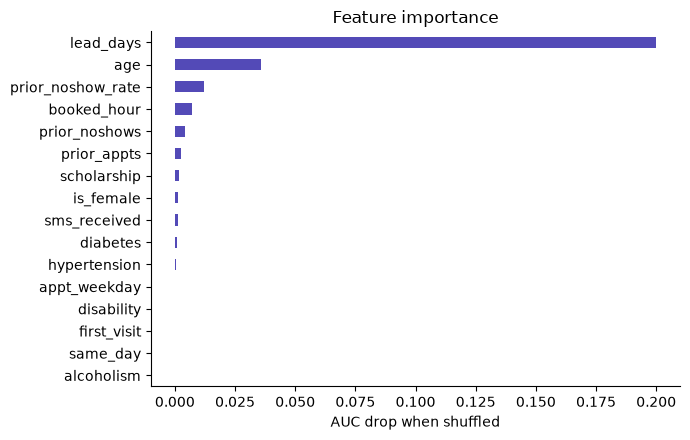

In [10]:
from sklearn.inspection import permutation_importance
final = make_models()[best].fit(pd.concat([train, val])[FEATURES], pd.concat([train, val])[TARGET])
sample = test.sample(8000, random_state=0)
imp = permutation_importance(final, sample[FEATURES], sample[TARGET], scoring="roc_auc", n_repeats=5, random_state=0)
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
ax = imp_s.plot.barh(color="#534AB7", figsize=(7, 4.5)); ax.set_xlabel("AUC drop when shuffled"); ax.set_title("Feature importance")
plt.tight_layout(); plt.savefig(ART / "feature_importance.png", dpi=160); plt.show()

## 4. Simulation: refilling no-show slots

Each day the clinic prompts a budget of patients (20% of appointments) to confirm. Anyone who doesn't confirm by 30 minutes before is released, and the slot is offered to nearby standby patients.

**Assumptions (not measured from the data, so state them in the pitch):**
- Patients who will attend confirm 80% of the time; eventual no-shows still confirm 10% of the time.
- On average 3 eligible standby patients are within radius, each claiming with 35% probability, so a released slot is refilled about 65% of the time.

A **double-booking** is when we release a slot, refill it, and the original patient shows up anyway. That's the cost side, and the reason to target carefully instead of prompting everyone.

In [11]:
sim = run_policies(test, p, budget=0.20)
pd.DataFrame({k: sim[k] for k in ["none", "random", "model", "everyone"]}).T[["prompts_sent", "recovered", "conflicts", "fill_rate", "recovered_per_conflict"]]

,prompts_sent,recovered,conflicts,fill_rate,recovered_per_conflict
none,0.000,0.000,0.000,0.000,NaN
random,8633.000,948.700,911.600,0.117,1.040
model,8633.000,1815.400,719.000,0.224,2.530
everyone,43161.000,4743.000,4557.500,0.585,1.040


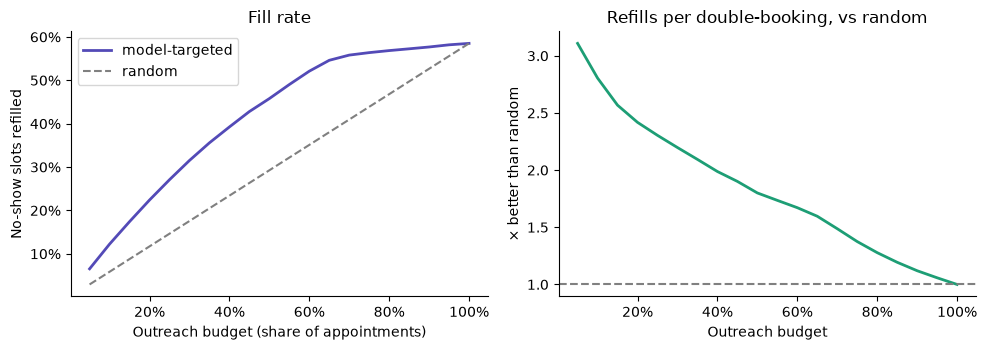

In [12]:
curve = pd.DataFrame(budget_curve(test, p))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.plot(curve.budget, curve.model_fill_rate, color="#534AB7", lw=2, label="model-targeted")
a1.plot(curve.budget, curve.random_fill_rate, "--", color="gray", label="random")
a1.set_xlabel("Outreach budget (share of appointments)"); a1.set_ylabel("No-show slots refilled"); a1.legend(); a1.set_title("Fill rate")
ratio_m = curve.model_fill_rate / curve.model_double_bookings_per_100
ratio_r = curve.random_fill_rate / curve.random_double_bookings_per_100
a2.plot(curve.budget, ratio_m / ratio_r, color="#1D9E75", lw=2)
a2.axhline(1, ls="--", color="gray"); a2.set_xlabel("Outreach budget"); a2.set_ylabel("× better than random"); a2.set_title("Refills per double-booking, vs random")
for a in (a1, a2): a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
a1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.savefig(ART / "budget_curve.png", dpi=160); plt.show()

In [13]:
m = json.loads((ART / "metrics.json").read_text())
print(f"Headline (from train.py, same numbers): with a 20% outreach budget the model refills "
      f"{m['fill_rate_ours']:.1%} of no-show slots vs {m['fill_rate_baseline']:.1%} picking at random "
      f"({m['fill_rate_ours']/m['fill_rate_baseline']:.1f}x), with {m['policies']['model']['recovered_per_conflict']} refills per double-booking "
      f"vs {m['policies']['random']['recovered_per_conflict']} for random.")

Headline (from train.py, same numbers): with a 20% outreach budget the model refills 22.4% of no-show slots vs 11.7% picking at random (1.9x), with 2.53 refills per double-booking vs 1.04 for random.


## 5. Takeaways and limitations
**Takeaways**
- Lead time and a patient's own history drive no-shows.
- The model is moderate (AUC ≈ 0.73), but targeting with it roughly doubles refills for the same outreach effort and cuts double-bookings per refill by more than half.

**Limitations (say these before a judge does)**
- Data is from Brazil in 2016, not Boston. The patterns (lead time, history) are well documented elsewhere, but the exact numbers won't transfer.
- No appointment time of day or specialty in the data.
- The confirmation and standby acceptance rates are assumptions. The budget curve shows how results move with outreach volume; rerun `run_policies` with different `assumptions` to stress-test.
- This dataset has neighbourhood names, not coordinates. Location matching in the app uses Synthea's synthetic Massachusetts residents instead; see notebook 02.